# Torch-Rechub 新手教程：使用DIN进行点击率预测
```text
本教程将带你一步步使用深度兴趣网络 (Deep Interest Network, DIN)来完成一个经典的点击率 (CTR) 预测任务。  
```
**什么是DIN？**  
```text
DIN（深度兴趣网络）是一个为点击率（CTR）预测设计的深度学习模型，它的核心创新在于动态地、有针对性地捕捉用户的兴趣。  
想象一下你在一个大型电商网站上的行为：  
过去一个月，你买了一部手机、一个手机壳、一本编程书和一双跑鞋;现在，网站要给你推荐一个新商品：蓝牙耳机。  
DIN会想：“等等，现在要推荐的是蓝牙耳机。那么，用户之前购买手机和手机壳的行为就非常相关，而购买编程书和跑鞋的行为相关性就小得多。”  
DIN通过引入“注意力机制（Attention Mechanism）”来实现这一点。它会用“候选商品”（蓝牙耳机）去“审视”你的整个历史行为序列，并为每个历史行为分配一个“注意力分数”或权重。 
其中，手机和手机壳会获得很高的权重，而编程书和跑鞋会获得很低的权重。
然后，DIN将这些历史行为的向量根据权重进行加权求和，生成一个为当前候选商品“量身定制”的用户兴趣向量。这个向量就精准地表达了你“对蓝牙耳机这类商品”的兴趣。  
总结：DIN的核心是，用户的兴趣表示不应该是固定的，而应该根据要预测的候选商品动态变化。  
```
**DIN与DeepFM的区别与联系是什么？**
```text  
联系与相似之处：  
最终目标相同：两者都是用于CTR预测的精排模型，目标是预测用户点击某个物品的概率。  
基础架构相似：它们都遵循“Embedding + MLP”的范式。即将高维稀疏的ID类特征（如user_id, item_id）通过Embedding层转换为低维稠密的向量，然后将这些向量输入到一个多层感知机（MLP / Deep Network）中学习复杂的非线性关系。  
核心区别：  
DeepFM的核心在于自动学习特征交叉。它将用户的user_id、历史行为（通常通过池化处理成一个固定的向量）、上下文特征等所有信息，看作是平等的输入。然后通过其经典的FM + DNN结构，将这些信息静态地融合在一起，学习它们之间复杂的组合关系，最终输出一个点击率预测。它回答的问题是：“综合这个用户的所有特征，他点击这个商品的概率是多少？”  
DIN则更进了一步，它认为用户的兴趣不是一成不变的，而是会被当前的“候选商品”动态激活。在处理用户历史行为时，它不再是简单地将所有行为“揉”成一团，而是引入了注意力机制。这个机制会用候选商品去“审视”用户的整个行为历史，并为每个历史行为分配一个权重——与候选商品越相关的行为，权重越高。这样，DIN为每一个不同的候选商品，都生成一个量身定制的、动态的用户兴趣表示。它回答的问题是：“考虑到现在要推荐的是这个商品，用户的哪些历史兴趣与此相关，并应该被重点关注？”  
```

**为什么这里要用到DIN？**  
```text
在本教程中，我们选择DIN而非DeepFM，是出于一个非常明确的教学目标：学习如何处理和利用用户的“行为序列”特征。  
我们的数据集是用户的商品交互日志，这天然就构成了时间序列。torch-rechub也为此提供了专门的工具create_seq_features和SequenceFeature类。DeepFM虽然也能处理这类数据，但它通过简单的池化操作，实际上“抹平”了序列内部的丰富信息，无法体现出序列建模的精髓。  
相比之下，DIN的设计初衷就是为了从行为序列中挖掘更深层次的、与特定目标相关的用户兴趣。通过学习DIN，你不仅能掌握一个更强大的模型，更重要的是，你能亲身体会到：  
注意力机制如何解决“用户兴趣多样性”这一核心推荐难题。  
如何定义和使用history_features和target_features，让它们在模型内部产生动态交互。   
```


## 0. 学习目标
- **场景**: 电商精排（CTR预测）
- **模型**: DIN
- **数据**: Amazon-Electronics (亚马逊电子产品评论) 样本数据集
- **技能**: 
    1. 掌握 `torch-rechub` 的核心使用流程：数据处理 -> 特征定义 -> 模型训练。
    2. 理解如何为序列推荐模型（如DIN）准备特征，特别是用户的历史行为序列。
    3. 能够独立使用 `torch-rechub` 快速搭建、训练和评估一个CTR预测模型。

## 1. 环境准备与导入

首先，我们需要安装 `torch-rechub` 并导入本教程所需的库。我们还会固定随机种子，以确保代码的可复现性。

In [1]:
# 如果你尚未安装，请取消注释并运行以下命令
# !pip install torch-rechub

import torch
import pandas as pd
from torch_rechub.models.ranking import DIN
from torch_rechub.trainers import CTRTrainer
from torch_rechub.basic.features import SparseFeature, SequenceFeature
from torch_rechub.utils.data import create_seq_features, df_to_dict, DataGenerator

# 固定随机种子以便复现
torch.manual_seed(2024)

# 检查PyTorch版本和CUDA可用性
print(f"PyTorch Version: {torch.__version__}, CUDA Available: {torch.cuda.is_available()}")

PyTorch Version: 2.9.1+cpu, CUDA Available: False


## 2. 数据加载与预处理

CTR预测任务通常始于用户的交互日志。我们的原始数据包含了 `user_id`, `item_id`, `cate_id`, 和 `time`。

为了训练DIN这样的序列模型，我们需要将这些零散的交互记录转换成包含**用户历史行为序列**的样本。幸运的是，`torch-rechub` 提供了一个便捷的工具函数 `create_seq_features` 来完成这项工作。它会自动：
1. 按用户和时间对交互进行排序。
2. 使用滑窗的方式为每个用户的行为序列生成多条训练样本。
3. 为每个样本构建历史行为序列 (history) 和目标物品 (target)。
4. 生成负样本以供模型学习区分。

In [2]:
# 加载样本数据集
# 注意：这是一个仅包含100行的小样本，用于快速演示。全量数据请参考官方文档。
file_path = '../../examples/ranking/data/amazon-electronics/amazon_electronics_sample.csv'
data = pd.read_csv(file_path)

# 使用内置函数构建序列特征
# seq_feature_col: 需要为其生成历史序列的列
# drop_short: 舍弃历史序列长度小于该值的用户
train_df, val_df, test_df = create_seq_features(data, seq_feature_col=['item_id', 'cate_id'], drop_short=0)

print("预处理后的训练数据样本:")
train_df.head()

预处理后的训练数据样本:


,user_id,history_item,history_cate,target_item,target_cate,label
0,9,"[63, 9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...","[16, 34, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0...",7,15,1
1,7,"[57, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...","[62, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",74,29,0
2,4,"[25, 19, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0...","[57, 13, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0...",91,21,1
3,16,"[16, 23, 65, 46, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...","[26, 26, 32, 23, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",34,5,0
4,14,"[29, 51, 52, 71, 92, 95, 22, 40, 0, 0, 0, 0, 0...","[36, 39, 34, 11, 28, 38, 1, 14, 0, 0, 0, 0, 0,...",85,12,0


## 3. 特征定义

现在我们有了处理好的数据，下一步是告诉模型如何理解每一列特征。在 `torch-rechub` 中，我们通过特定的 `Feature` 类来定义不同类型的特征。

- **SparseFeature**: 用于离散的类别特征，如 `user_id`、`item_id`。模型会为这类特征创建一个Embedding层。
- **SequenceFeature**: 用于序列特征，如 `history_item`。它本质上是一系列的 `SparseFeature`。

一个关键点是，**目标物品 (target_item)** 和 **历史序列中的物品 (history_item)** 应该共享同一个 Embedding 词表。我们可以通过 `shared_with` 参数轻松实现这一点，这有助于模型学习和泛化。

In [3]:
# 计算特征的词表大小 (vocabulary size)，为Embedding层做准备
# +2 是为了容纳padding位(0)和未登录(UNK)位(1)
n_users = data["user_id"].max() + 2
n_items = data["item_id"].max() + 2
n_cates = data["cate_id"].max() + 2
EMBED_DIM = 64

# 1. 定义用户和目标物品特征 (target features)
features = [
    SparseFeature("user_id", vocab_size=n_users, embed_dim=EMBED_DIM),
    SparseFeature("target_item", vocab_size=n_items, embed_dim=EMBED_DIM),
    SparseFeature("target_cate", vocab_size=n_cates, embed_dim=EMBED_DIM)
]

# 2. 单独指定哪些是目标物品特征，DIN需要用它来计算Attention
target_features = [features[1], features[2]]

# 3. 定义历史序列特征 (history features)
history_features = [
    SequenceFeature("history_item", vocab_size=n_items, embed_dim=EMBED_DIM, pooling="concat", shared_with="target_item"),
    SequenceFeature("history_cate", vocab_size=n_cates, embed_dim=EMBED_DIM, pooling="concat", shared_with="target_cate")
]

## 4. 模型构建与训练

万事俱备！现在我们可以进入最激动人心的部分了。我们将执行以下步骤：
1.  **准备DataLoader**: 使用 `df_to_dict` 和 `DataGenerator` 将 `DataFrame` 转换为模型训练所需的数据管道。
2.  **构建DIN模型**: 实例化 `DIN` 模型，并将我们刚刚定义好的特征列表传入。我们还可以通过 `mlp_params` 等参数自定义模型的网络结构。
3.  **启动训练器**: 使用 `CTRTrainer` 来管理整个训练流程。它封装了常见的训练循环、验证、早停 (early stopping) 和评估逻辑，让我们可以用几行代码就完成模型训练。

In [4]:
# 1. 准备DataLoader
# 将DataFrame转换为字典格式
train_x, val_x, test_x = df_to_dict(train_df), df_to_dict(val_df), df_to_dict(test_df)
train_y, val_y, test_y = train_df['label'].values, val_df['label'].values, test_df['label'].values

# 创建数据生成器
dg = DataGenerator(train_x, train_y)
train_dataloader, val_dataloader, test_dataloader = dg.generate_dataloader(
    x_val=val_x, y_val=val_y, x_test=test_x, y_test=test_y, batch_size=16
)

# 2. 构建DIN模型
model = DIN(
    features=features, 
    history_features=history_features, 
    target_features=target_features, 
    mlp_params={"dims": [256, 128]},
    attention_mlp_params={"dims": [256, 128]}
)
# 3. 使用CTRTrainer进行训练和评估
ctr_trainer = CTRTrainer(
    model,
    optimizer_params={"lr": 1e-3, "weight_decay": 1e-3},
    n_epoch=5,
    earlystop_patience=2,
    device='cpu',  # 如果有GPU，可以设置为 'cuda:0'
    model_path='./'
)

# 启动训练
ctr_trainer.fit(train_dataloader, val_dataloader)

# 在测试集上评估模型性能
auc = ctr_trainer.evaluate(ctr_trainer.model, test_dataloader)
print(f'Test AUC: {auc:.4f}')

epoch: 0


validation: 100%|██████████| 2/2 [00:00<00:00, 251.68it/s]


epoch: 0 validation: auc: 0.513671875
epoch: 1


validation: 100%|██████████| 2/2 [00:00<00:00, 245.38it/s]


epoch: 1 validation: auc: 0.3671875
epoch: 2


validation: 100%|██████████| 2/2 [00:00<00:00, 257.31it/s]


epoch: 2 validation: auc: 0.32421875
validation: best auc: 0.513671875


validation: 100%|██████████| 2/2 [00:00<00:00, 242.93it/s]

Test AUC: 0.6328


## 总结
恭喜你！你已经成功地使用 `torch-rechub` 训练了一个 DIN 模型。

回顾一下，我们通过三个核心步骤完成了整个过程：
1. **数据处理**: 使用 `create_seq_features` 将原始日志转换为包含历史序列的样本。
2. **特征定义**: 使用 `SparseFeature` 和 `SequenceFeature` 向模型描述了每个特征的类型和属性。
3. **模型训练**: 实例化 `DIN` 模型和 `CTRTrainer`，用简洁的代码完成了模型的训练与评估。

希望本教程能帮助你快速上手 `torch-rechub`。现在，你可以尝试在更大的数据集上运行，或者探索 `torch-rechub` 中其他有趣的模型！

# 附录：DIN模型可视化

In [5]:
from torch_rechub.utils.visualization import visualize_model
graph = visualize_model(model, depth=40)

DIN模型的结构如下：
```text
DIN(
  (embedding): EmbeddingLayer(
    (embed_dict): ModuleDict(
      (user_id): Embedding(19, 64)
      (target_item): Embedding(101, 64)
      (target_cate): Embedding(69, 64)
    )
  )
  (attention_layers): ModuleList(
    (0-1): 2 x ActivationUnit(
      (attention): MLP(
        (mlp): Sequential(
          (0): Linear(in_features=256, out_features=256, bias=True)
          (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): Dice()
          (3): Dropout(p=0, inplace=False)
          (4): Linear(in_features=256, out_features=128, bias=True)
          (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (6): Dice()
          (7): Dropout(p=0, inplace=False)
          (8): Linear(in_features=128, out_features=1, bias=True)
        )
      )
    )
  )
  (mlp): MLP(
    (mlp): Sequential(
      (0): Linear(in_features=448, out_features=256, bias=True)
      (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): Dice()
      (3): Dropout(p=0, inplace=False)
      (4): Linear(in_features=256, out_features=128, bias=True)
      (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): Dice()
      (7): Dropout(p=0, inplace=False)
      (8): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)
```
一共分为三部分：  
输入与嵌入层 (EmbeddingLayer): 负责将所有输入的离散ID类特征转换为低维稠密的向量。  
注意力与兴趣激活层 (attention_layers): DIN模型的核心，负责根据目标商品动态地计算用户历史行为的权重，并生成一个“激活的”用户兴趣向量。  
预测层 (MLP): 一个标准的多层感知机，负责整合所有特征向量并输出最终的点击率预测值。  
1. 第一部分：输入与嵌入层 (EmbeddingLayer)  
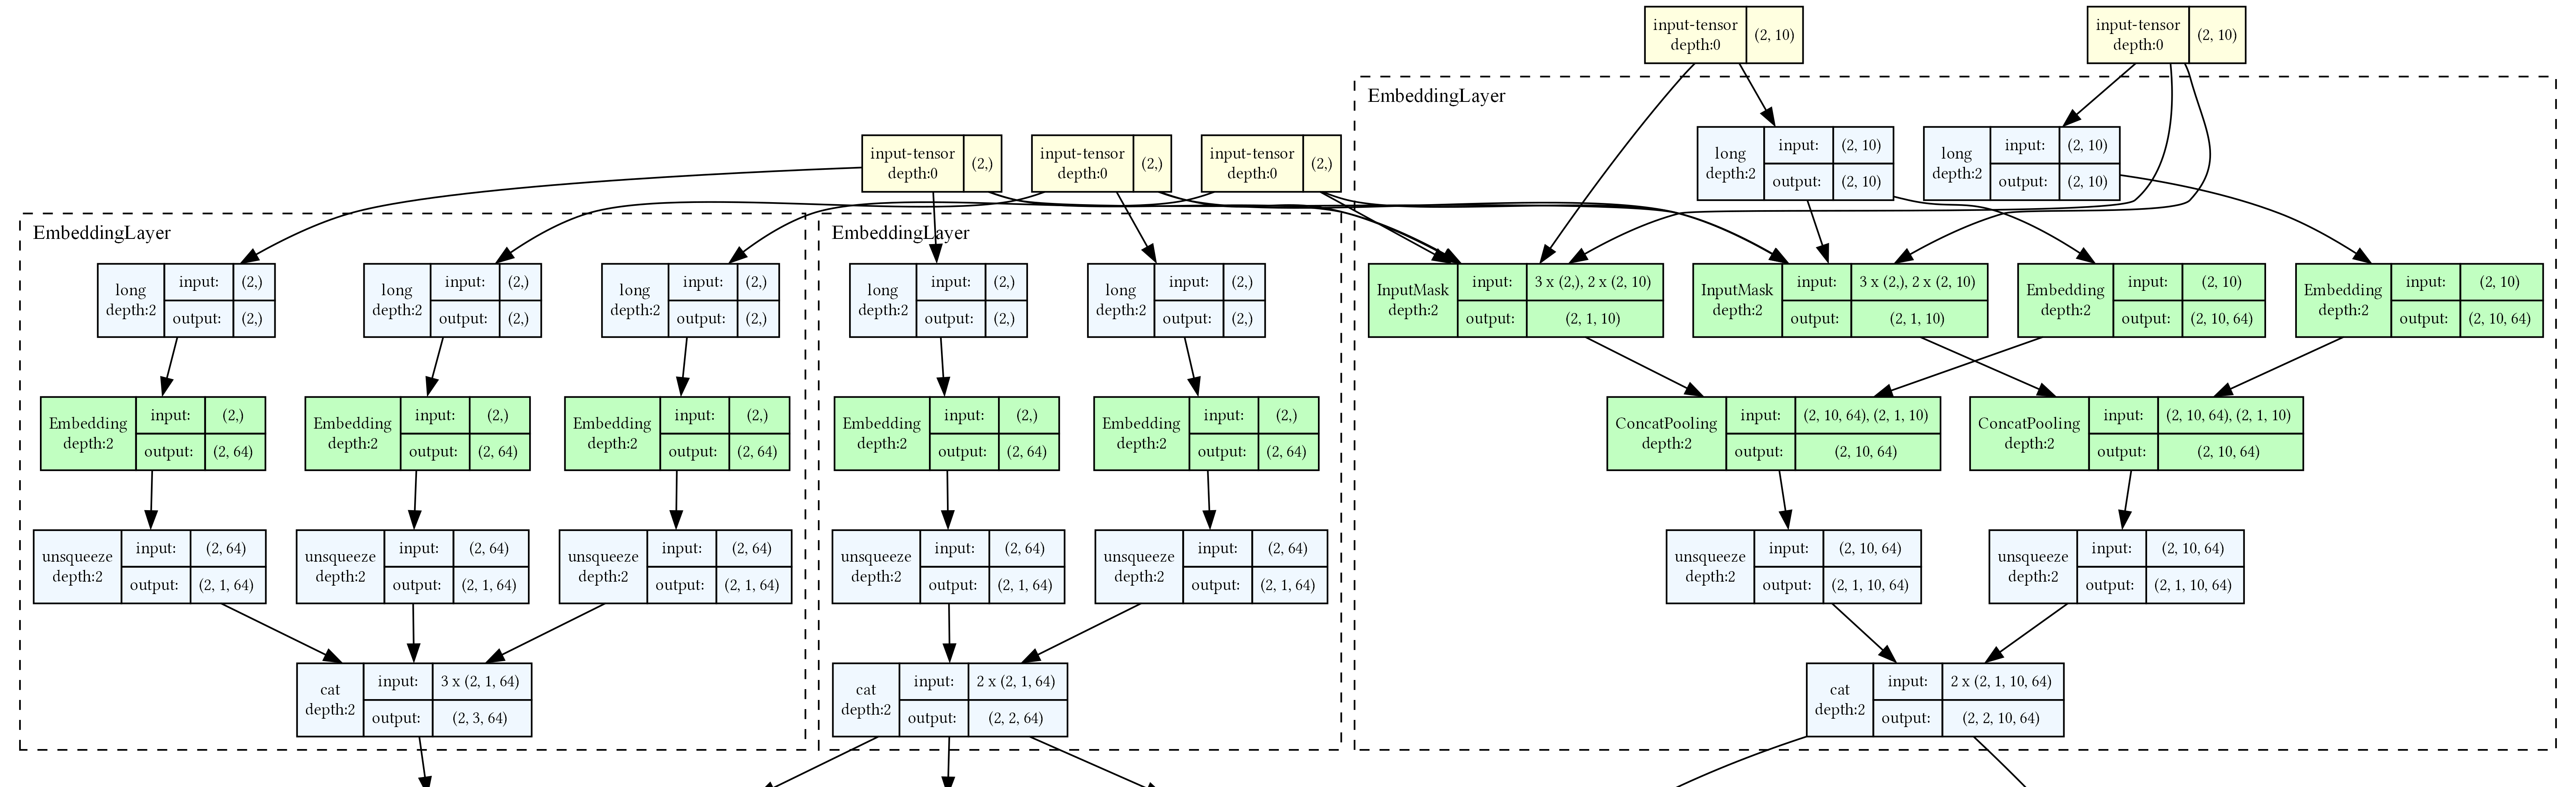
```text
(embedding): EmbeddingLayer(
  (embed_dict): ModuleDict(
    (user_id): Embedding(19, 64)
    (target_item): Embedding(101, 64)
    (target_cate): Embedding(69, 64)
  )
)
EmbeddingLayer: 这是模型的数据入口。它的作用是将输入的、高维稀疏的类别特征（例如，user_id=10）映射成低维稠密的浮点数向量（即Embedding）。
ModuleDict: 这是一个字典结构，用于存储各个特征独立的Embedding层。这样做的好处是结构清晰，易于管理。
user_id: Embedding(19, 64):
19: 代表user_id这个特征的词表大小（Vocabulary Size），意味着系统中有18个唯一的用户ID（通常0被保留给padding或未知值）。
64: 代表嵌入维度（Embedding Dimension），即将每个user_id都转换成一个64维的向量。
target_item 和 target_cate: 同理，它们分别是为目标商品ID和目标品类ID创建的嵌入层。
关于序列特征: 虽然这里没有显式列出history_item和history_cate的嵌入层，但torch-rechub的实现中，序列特征会与对应的目标特征共享同一个嵌入层。例如，history_item会使用target_item的Embedding(101, 64)层来查找其 embedding 向量。这是一种非常重要的参数共享机制，可以减少模型参数量并提升泛化能力。
```
2. 第二部分：注意力与兴趣激活层 (attention_layers)  
这是DIN模型最关键的部分。  
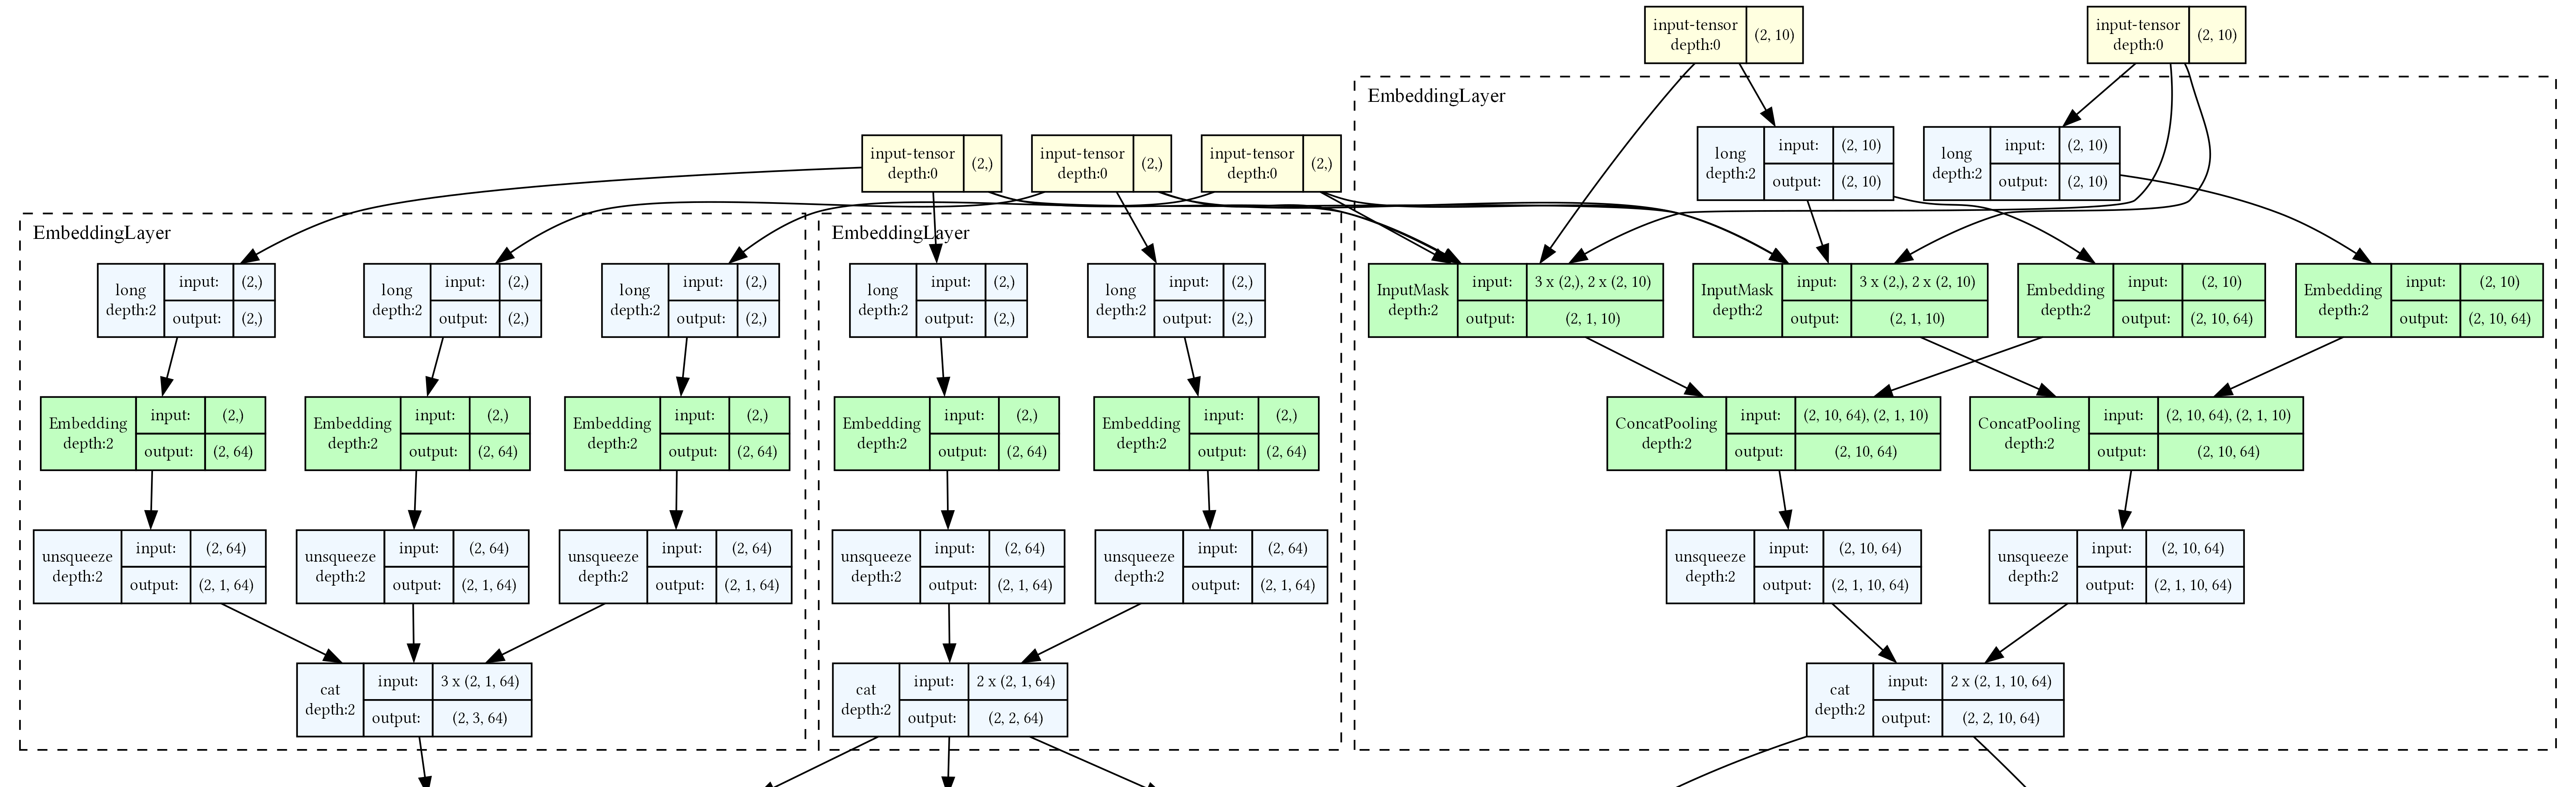
```text
(attention_layers): ModuleList(
  (0-1): 2 x ActivationUnit(
    (attention): MLP(...)
  )
)
功能解析:
ModuleList: 这是一个列表，用于存放多个注意力计算单元。这里的2 x ActivationUnit表明模型中有两个独立的ActivationUnit实例。这是因为我们有两个序列特征需要处理：history_item和history_cate。每一个ActivationUnit负责处理一个序列。
ActivationUnit: 这是实现注意力机制的核心模块。它的输入是目标物品的Embedding和整个历史行为序列的Embedding。它的输出是经过注意力加权求和后的、代表用户动态兴趣的单一向量。
```
ActivationUnit内部的MLP结构图：  
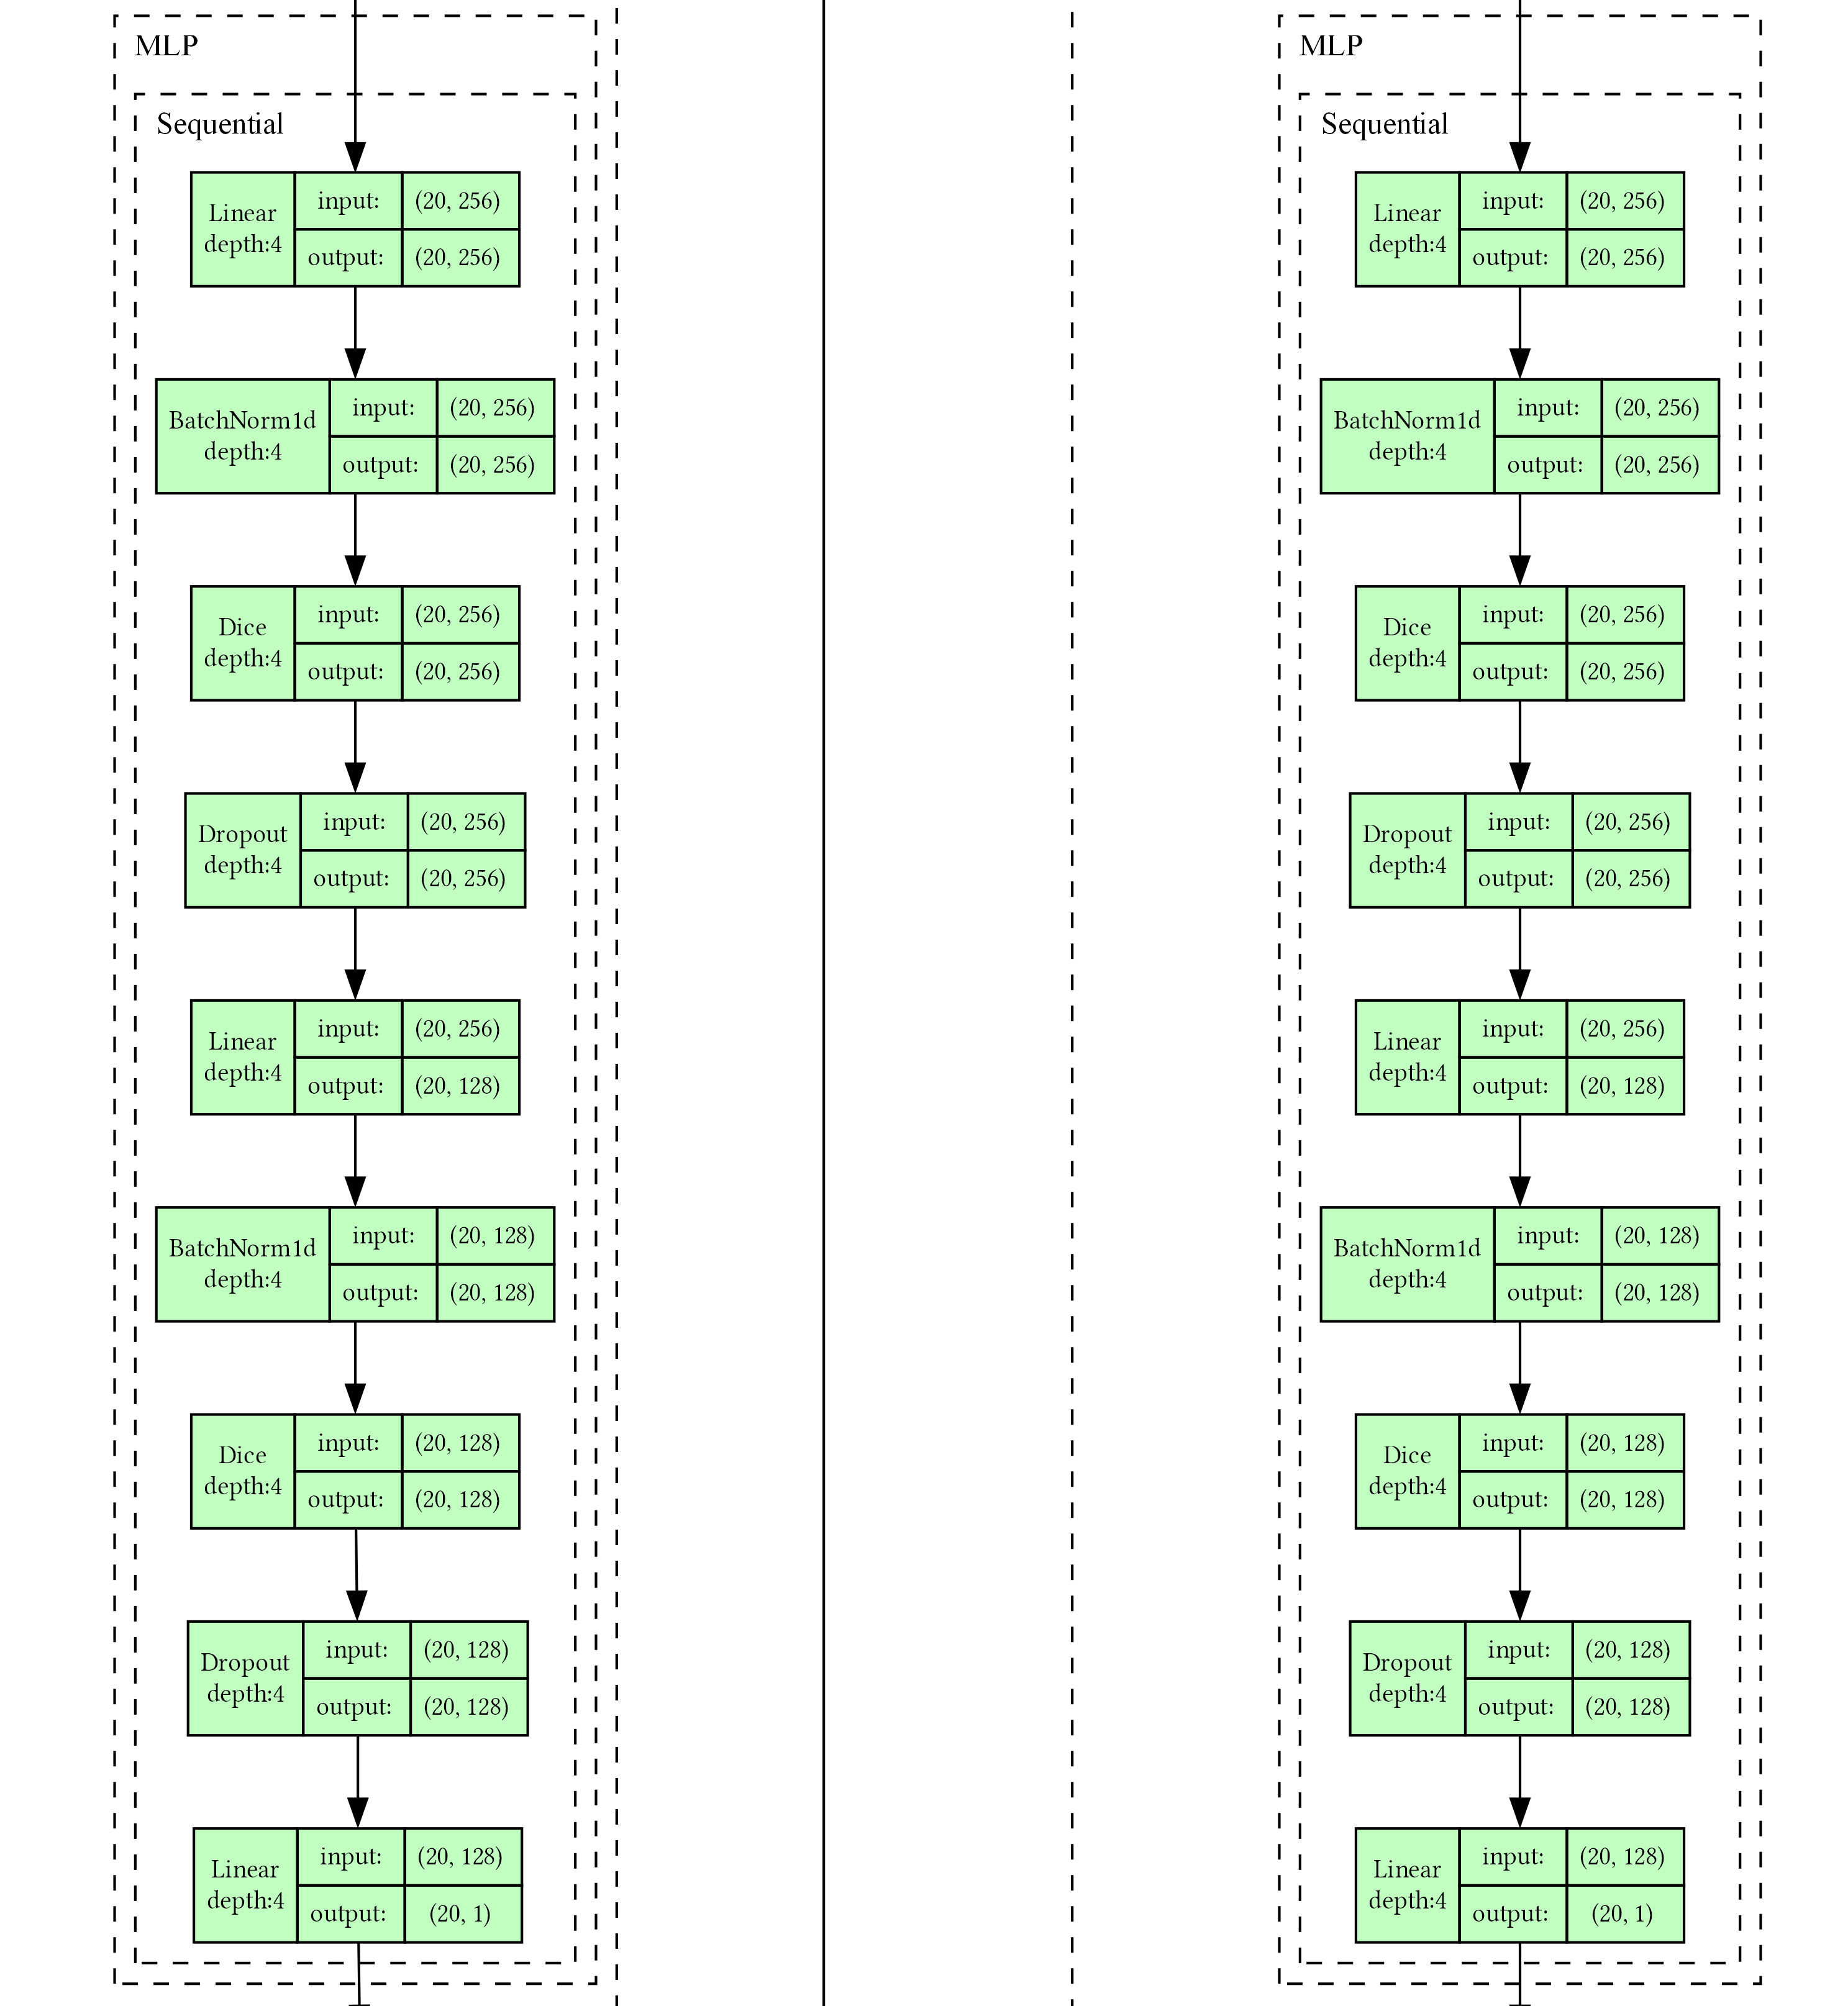
```text
      (attention): MLP(
        (mlp): Sequential(
          (0): Linear(in_features=256, out_features=256, bias=True)
          (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): Dice()
          (3): Dropout(p=0, inplace=False)
          (4): Linear(in_features=256, out_features=128, bias=True)
          (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (6): Dice()
          (7): Dropout(p=0, inplace=False)
          (8): Linear(in_features=128, out_features=1, bias=True)
        )
      )
功能解析:
这个MLP的作用: 它的唯一目标是为历史序列中的每一个物品计算一个注意力分数（Attention Score）。这个分数衡量了该历史物品与当前目标物品的“相关性”。
输入 (in_features=256): 这个MLP的输入不是单个Embedding。对于历史序列中的每一个物品，输入是由以下几部分拼接（Concatenate）而成的：
目标物品的Embedding (64维)
当前历史物品的Embedding (64维)
目标物品与历史物品Embedding的逐元素相减结果 (64维)
目标物品与历史物品Embedding的逐元素相乘结果 (64维)
总维度 = 64 + 64 + 64 + 64 = 256维。这种拼接方式为MLP提供了丰富的交互信息，以便其判断相关性。
中间层:
Linear: 线性变换层，用于学习特征间的高阶非线性关系。
BatchNorm1d: 批归一化，用于稳定和加速训练过程。
Dice: DIN论文中提出的一种数据自适应的激活函数，可以看作是PReLU的泛化，能根据数据分布调整激活点。
Dropout: 正则化技术，防止模型过拟合。
输出 (out_features=1): 经过多层网络计算后，最终的Linear层输出一个标量（Scalar）。这个标量就是该历史物品相对于目标物品的原始注意力分数。
ActivationUnit后续操作（模型结构中未打印）
对一个序列中的所有历史物品，重复上述过程，得到一组注意力分数。
将这组分数通过Softmax函数进行归一化，得到一组权重，所有权重之和为1。
用这些权重对历史物品的原始Embedding进行加权求和（Weighted Sum）。
最终得到一个64维的向量，这就是“被激活的”用户兴趣向量。
```
3. 第三部分：预测层 (MLP)  
在计算出history_item和history_cate各自的激活兴趣向量后，模型会将它们与所有其他特征的Embedding向量（user_id, target_item, target_cate）拼接在一起，形成一个大的向量。  
这个大向量会被送入模型最后的预测MLP中（结构与attention中的MLP类似）。  
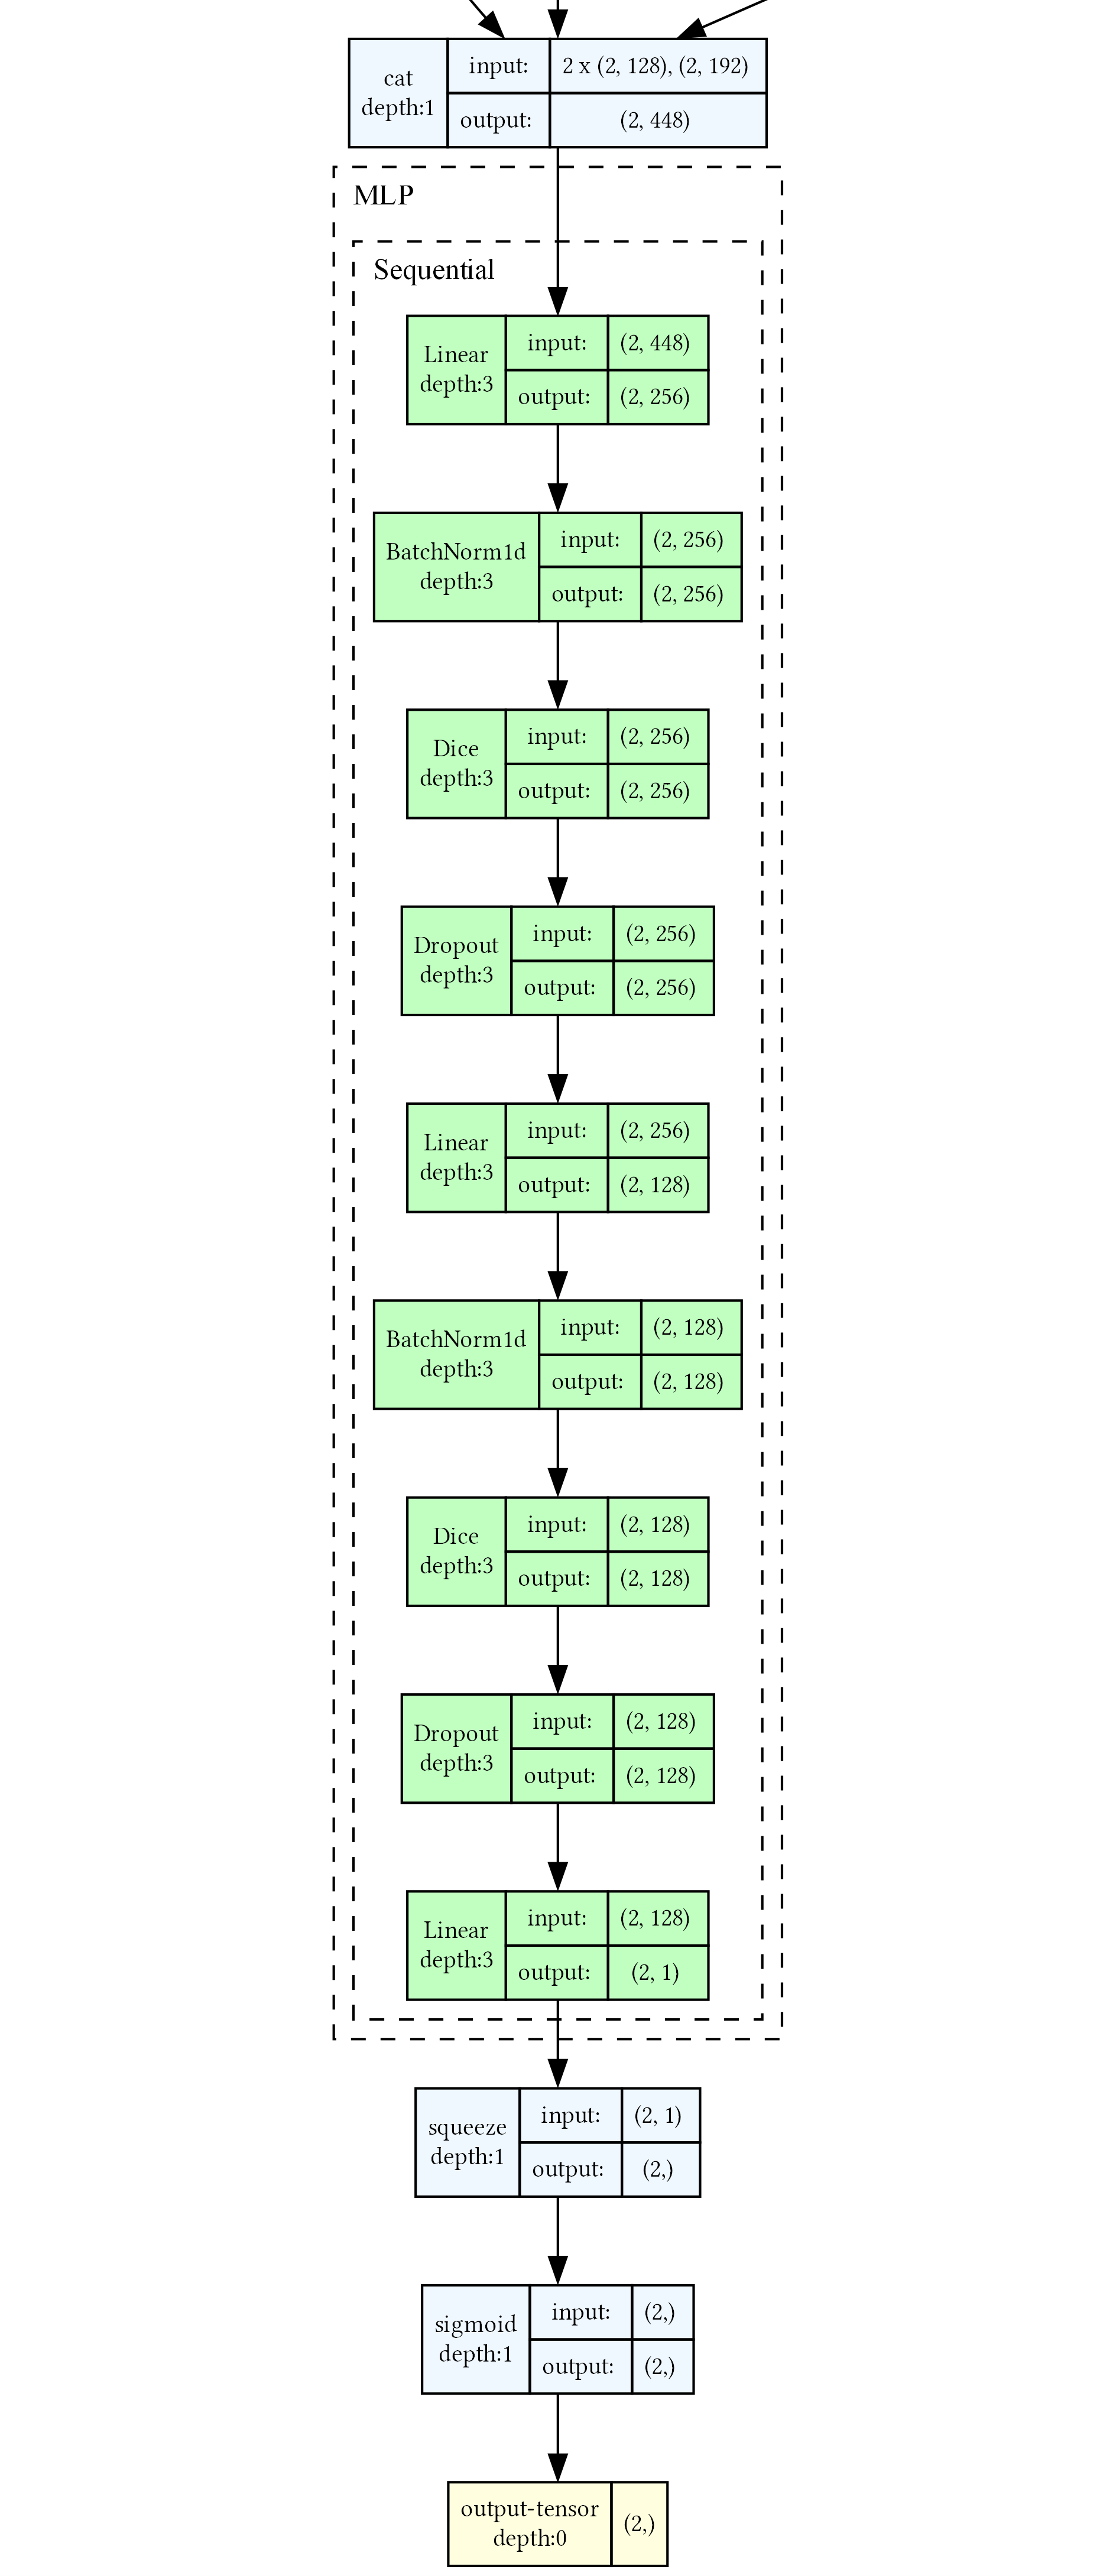
```text
  (mlp): MLP(
    (mlp): Sequential(
      (0): Linear(in_features=448, out_features=256, bias=True)
      (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): Dice()
      (3): Dropout(p=0, inplace=False)
      (4): Linear(in_features=256, out_features=128, bias=True)
      (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): Dice()
      (7): Dropout(p=0, inplace=False)
      (8): Linear(in_features=128, out_features=1, bias=True)
    )
  )
功能解析:
输入: 所有特征（包括被激活的兴趣向量）拼接后的大向量。
功能: 这个MLP的作用是学习所有可用信息之间的最终高阶组合关系。
输出 (out_features=1): 最终，它输出一个单一的数值（Logit）。这个Logit会经过一个Sigmoid函数（通常在损失函数计算时隐式调用），转换为一个0到1之间的概率值，即最终的CTR预测结果。
```


**下段代码作用**：展示模型结构。

In [6]:
print(model)

DIN(
  (embedding): EmbeddingLayer(
    (embed_dict): ModuleDict(
      (user_id): Embedding(19, 64)
      (target_item): Embedding(101, 64)
      (target_cate): Embedding(69, 64)
    )
    (input_mask): InputMask()
  )
  (attention_layers): ModuleList(
    (0-1): 2 x ActivationUnit(
      (attention): MLP(
        (mlp): Sequential(
          (0): Linear(in_features=256, out_features=256, bias=True)
          (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): Dice()
          (3): Dropout(p=0, inplace=False)
          (4): Linear(in_features=256, out_features=128, bias=True)
          (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (6): Dice()
          (7): Dropout(p=0, inplace=False)
          (8): Linear(in_features=128, out_features=1, bias=True)
        )
      )
    )
  )
  (mlp): MLP(
    (mlp): Sequential(
      (0): Linear(in_features=448, out_features=256, bias=True)
      (1): 